<a href="https://colab.research.google.com/github/Janith303/Sinhala-and-Maths-Model-training-/blob/Naive-Bayes/notebooks/NB_Slow_Learner_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Naive Bayes — Slow Learner Identification (Maths)
A step-by-step notebook that trains **one model: Gaussian Naive Bayes**, checks all evaluation metrics, and exports the model file.

**How to use in Colab:** Runtime → Run all. When Step 1 asks, upload `Maths_operation_data.xlsx`.

**What we predict:** `Slow` (positive class, = 1) vs `Normal` (= 0).

**Naive Bayes in one line:** for each class (Slow / Normal) it learns the typical average and spread of every feature, then asks "which class makes this attempt's values more likely?" and combines that with how common each class is. It is very fast, works with small datasets, and its output is easy to explain.

**Two Naive Bayes-specific things to know:**
* It *assumes the features are independent of each other* ("naive"). Here that is not fully true (e.g. `Total_Time` and `Carry_Over_Time` move together), so its probabilities tend to be over-confident (close to 0 or 1). Its ranking (ROC-AUC) is often better than its raw predictions
* It uses the **class prior** (how common Slow is, ~21%). That pushes it towards Normal. In Step 8 we test an equal prior (50/50) to catch more slow learners

| Step | What happens |
|---|---|
| 1 | Load data |
| 2 | Look at the data |
| 3 | Choose features |
| 4 | Split into train / test |
| 5 | Train the Naive Bayes |
| 6 | Evaluate (Accuracy, Precision, Recall, F1, ROC-AUC …) |
| 7 | Cross-validation |
| 8 | Tune the model (var_smoothing, class prior) |
| 9 | Understand the model (per-class averages, threshold) |
| 10 | Save the model file and download |

## Step 1 — Load the data

In [1]:
import os, json, joblib, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

FILE = 'Maths_operation_data.xlsx'
if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()          # choose Maths_operation_data.xlsx
    FILE = list(uploaded.keys())[0]

df = pd.read_excel(FILE)
print('Rows, columns:', df.shape)
df.head()

Saving Maths operation data.xlsx to Maths operation data.xlsx
Rows, columns: (297, 7)


,No,Operation_Type,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests,Student_Label
0,1,Addition,2.10,2.10,0,0,Normal
1,2,Addition,1.89,1.89,0,0,Normal
2,3,Addition,2.62,2.62,0,0,Normal
3,4,Addition,3.07,3.07,0,0,Normal
4,5,Division,8.20,8.20,0,0,Normal


## Step 2 — Look at the data

In [2]:
print('Missing values:'); print(df.isna().sum().to_string())
print('\nClass counts:'); print(df['Student_Label'].value_counts())
print('\nAverages per class:')
df.groupby('Student_Label')[['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']].mean().round(2)

Missing values:
No                 0
Operation_Type     0
Total_Time         0
Carry_Over_Time    0
Erasure_Count      0
Hint_Requests      0
Student_Label      0

Class counts:
Student_Label
Normal    234
Slow       63
Name: count, dtype: int64

Averages per class:


,Total_Time,Carry_Over_Time,Erasure_Count,Hint_Requests
Student_Label,,,,
Normal,10.54,9.17,0.05,0.00
Slow,54.30,44.29,0.60,0.65


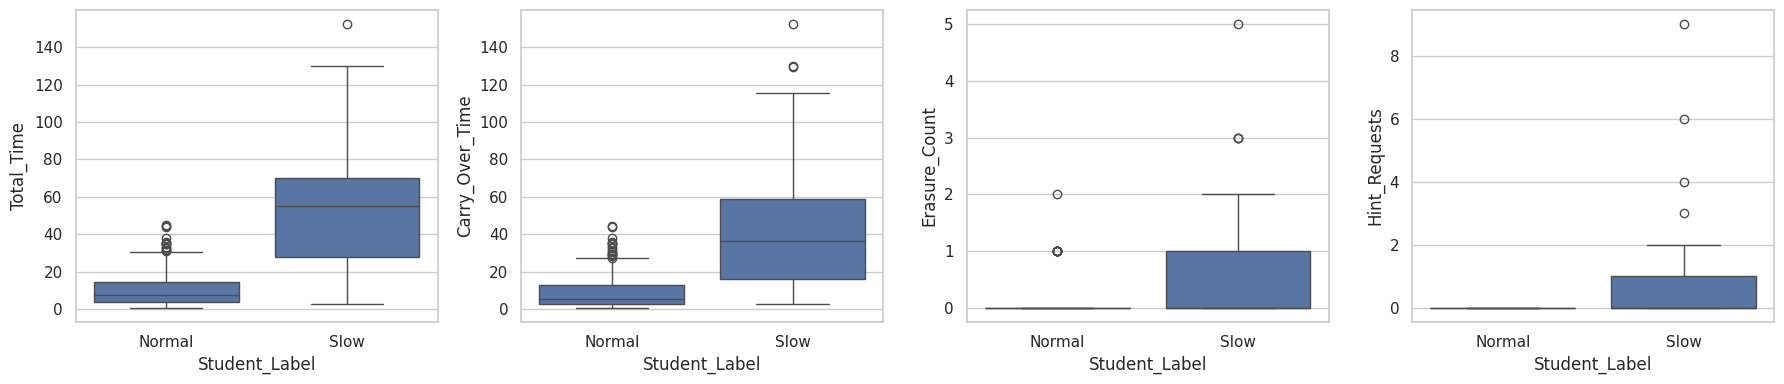

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col in zip(ax, ['Total_Time','Carry_Over_Time','Erasure_Count','Hint_Requests']):
    sns.boxplot(data=df, x='Student_Label', y=col, ax=a)
plt.tight_layout(); plt.show()

**Notice:** only about 21% of rows are `Slow`. *Accuracy alone is misleading* (always predicting "Normal" gets ~79%). Watch **Recall** and **F1** for the Slow class.

## Step 3 — Choose features
* **`USE_HINTS`** — `Hint_Requests` is 0 for *every* Normal row, so it almost gives away the answer. Run once with `True` and once with `False`, and report both.
* Extra features: `Carry_Ratio` (carry-over ÷ total time) and `Non_Carry_Time`.
* `Total_Time` has a long right tail (max ≈ 152 s), so the **log** makes them closer to the bell-curve shape Gaussian Naive Bayes assumes of the time columns. We add `log_` versions and drop the raw ones.

In [4]:
USE_HINTS = True      # <- change to False and re-run to test without Hint_Requests

data = df.copy()
data['Slow'] = (data['Student_Label'] == 'Slow').astype(int)      # 1 = Slow, 0 = Normal
data['Carry_Ratio'] = data['Carry_Over_Time'] / data['Total_Time']
data['Non_Carry_Time'] = data['Total_Time'] - data['Carry_Over_Time']
data['Log_Total_Time'] = np.log1p(data['Total_Time'])
data['Log_Carry_Time'] = np.log1p(data['Carry_Over_Time'])

num_cols = ['Log_Total_Time', 'Log_Carry_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time']
if USE_HINTS: num_cols.append('Hint_Requests')
cat_cols = ['Operation_Type']
FEATURES = num_cols + cat_cols

X = data[FEATURES]
y = data['Slow']
print('Features used:', FEATURES)

Features used: ['Log_Total_Time', 'Log_Carry_Time', 'Erasure_Count', 'Carry_Ratio', 'Non_Carry_Time', 'Hint_Requests', 'Operation_Type']


## Step 4 — Split into train (80%) and test (20%)
The test set is **kept hidden** until evaluation. `stratify=y` keeps the Slow/Normal ratio the same in both parts.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train rows:', len(X_train), '| Test rows:', len(X_test))
print('Slow share  train:', round(y_train.mean(), 3), ' test:', round(y_test.mean(), 3))

Train rows: 237 | Test rows: 60
Slow share  train: 0.211  test: 0.217


## Step 5 — Train the Naive Bayes (first version)
Inside one `Pipeline`: **OneHotEncoder** (turns `Operation_Type` into 0/1 columns) + **GaussianNB**. (Scaling is not needed — Naive Bayes is not affected by feature scale — but the StandardScaler is kept so the pipeline looks the same as the other notebooks and stays numerically stable.)
* `var_smoothing` adds a small amount to every variance so that a feature with almost no spread (e.g. `Hint_Requests` is 0 for every Normal row) cannot make the probability explode.
* `priors=None` means the prior is learned from the data (~79% Normal / 21% Slow).

In [6]:
def make_model(**nb_params):
    prep = ColumnTransformer([('num', StandardScaler(), num_cols),
                              ('op', OneHotEncoder(handle_unknown='ignore'), cat_cols)])
    nb = GaussianNB(**nb_params)
    return Pipeline([('prep', prep), ('nb', nb)])

nb_model = make_model(var_smoothing=1e-9)       # a sensible first model
nb_model.fit(X_train, y_train)
print('Trained!')

Trained!


## Step 6 — Evaluate on the test set
| Metric | Meaning (for the Slow class) |
|---|---|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of the students predicted Slow, how many really are Slow |
| **Recall** | Of the truly Slow students, how many we caught (missed ones hurt most) |
| **F1** | Balance between Precision and Recall |
| **Specificity** | Of the truly Normal students, how many we correctly called Normal |
| **ROC-AUC** | How well the model ranks Slow above Normal (1.0 = perfect, 0.5 = guessing) |
| **MCC** | Overall quality for imbalanced data (1 = perfect, 0 = random) |

In [7]:
def evaluate(model, X_, y_, title='', threshold=0.5):
    prob = model.predict_proba(X_)[:, 1]
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred).ravel()
    m = {'Accuracy': accuracy_score(y_, pred), 'Balanced Accuracy': balanced_accuracy_score(y_, pred),
         'Precision': precision_score(y_, pred, zero_division=0), 'Recall': recall_score(y_, pred),
         'F1': f1_score(y_, pred), 'Specificity': tn / (tn + fp), 'ROC-AUC': roc_auc_score(y_, prob),
         'MCC': matthews_corrcoef(y_, pred)}
    print(title); display(pd.Series(m, name='score').round(3).to_frame())
    print(f'TP={tp} (slow caught)  FN={fn} (slow missed)  FP={fp} (false alarm)  TN={tn}')
    return m, pred, prob

m1, pred1, prob1 = evaluate(nb_model, X_test, y_test, '=== Test-set results (first model) ===')

=== Test-set results (first model) ===


,score
Accuracy,0.917
Balanced Accuracy,0.808
Precision,1.000
Recall,0.615
F1,0.762
Specificity,1.000
ROC-AUC,0.961
MCC,0.746


TP=8 (slow caught)  FN=5 (slow missed)  FP=0 (false alarm)  TN=47


              precision    recall  f1-score   support

      Normal       0.90      1.00      0.95        47
        Slow       1.00      0.62      0.76        13

    accuracy                           0.92        60
   macro avg       0.95      0.81      0.86        60
weighted avg       0.92      0.92      0.91        60



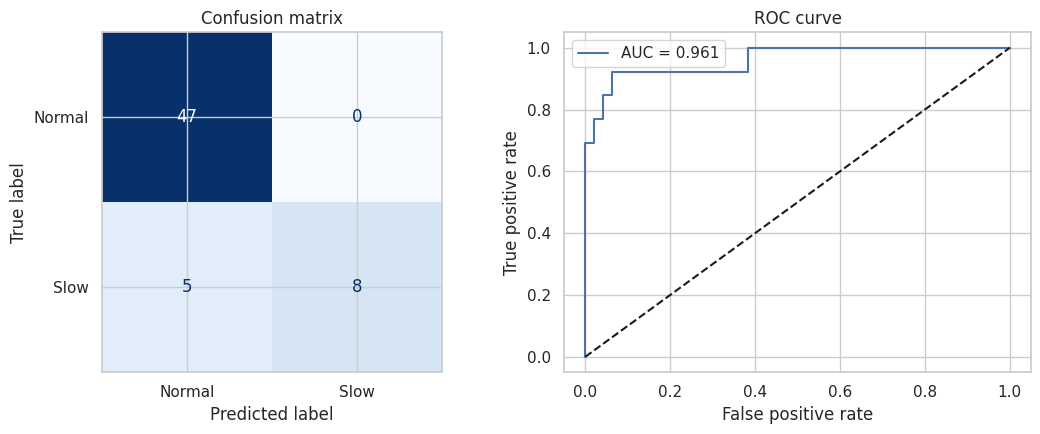

In [8]:
print(classification_report(y_test, pred1, target_names=['Normal', 'Slow']))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred1), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion matrix')
fpr, tpr, _ = roc_curve(y_test, prob1)
ax[1].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, prob1):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--')
ax[1].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()

In [9]:
# Overfitting check: a big gap between train and test means the model memorised the training data
print('Train accuracy:', round(accuracy_score(y_train, nb_model.predict(X_train)), 3))
print('Test  accuracy:', round(accuracy_score(y_test,  nb_model.predict(X_test)), 3))
print('Train F1      :', round(f1_score(y_train, nb_model.predict(X_train)), 3))
print('Test  F1      :', round(f1_score(y_test,  nb_model.predict(X_test)), 3))

Train accuracy: 0.899
Test  accuracy: 0.917
Train F1      : 0.7
Test  F1      : 0.762


## Step 7 — Cross-validation (more reliable)
The test set is small (60 rows). 5-fold cross-validation trains and tests 5 times on different parts of the training data and averages the results. The **± value** shows how much the score varies.

In [10]:
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
res = cross_validate(make_model(var_smoothing=1e-9), X_train, y_train, cv=cv, scoring=scoring)
pd.DataFrame({k: [res[f'test_{k}'].mean(), res[f'test_{k}'].std()] for k in scoring}, index=['mean', 'std']).T.round(3)

,mean,std
accuracy,0.890,0.027
precision,0.911,0.119
recall,0.560,0.150
f1,0.672,0.118
roc_auc,0.884,0.059


## Step 8 — Tune the model
Two settings matter:
* **var_smoothing** — how much extra variance is added (larger = smoother, less over-confident).
* **priors** — the assumed share of Slow vs Normal. `None` = learned from data (~21% Slow). `[0.5, 0.5]` = treat both classes as equally likely, which makes the model flag Slow more readily (higher Recall, lower Precision). `[0.7, 0.3]` is in between.

We try every combination and keep the best **F1** (change `TUNE_SCORING` to `'recall'` if you mostly care about not missing slow learners).

In [11]:
TUNE_SCORING = 'f1'
param_grid = {
    'nb__var_smoothing': [1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1],
    'nb__priors':        [None, [0.7, 0.3], [0.5, 0.5]],
}
search = GridSearchCV(make_model(), param_grid, cv=cv, scoring=TUNE_SCORING, n_jobs=-1)
search.fit(X_train, y_train)
print('Best settings :', search.best_params_)
print(f'Best CV {TUNE_SCORING}  :', round(search.best_score_, 3))
best_nb = search.best_estimator_

Best settings : {'nb__priors': [0.5, 0.5], 'nb__var_smoothing': 0.1}
Best CV f1  : 0.675


In [12]:
m2, pred2, prob2 = evaluate(best_nb, X_test, y_test, '=== Test-set results (tuned model) ===')
pd.DataFrame({'First model': m1, 'Tuned model': m2}).round(3)

=== Test-set results (tuned model) ===


,score
Accuracy,0.917
Balanced Accuracy,0.863
Precision,0.833
Recall,0.769
F1,0.800
Specificity,0.957
ROC-AUC,0.966
MCC,0.748


TP=10 (slow caught)  FN=3 (slow missed)  FP=2 (false alarm)  TN=45


,First model,Tuned model
Accuracy,0.917,0.917
Balanced Accuracy,0.808,0.863
Precision,1.000,0.833
Recall,0.615,0.769
F1,0.762,0.800
Specificity,1.000,0.957
ROC-AUC,0.961,0.966
MCC,0.746,0.748


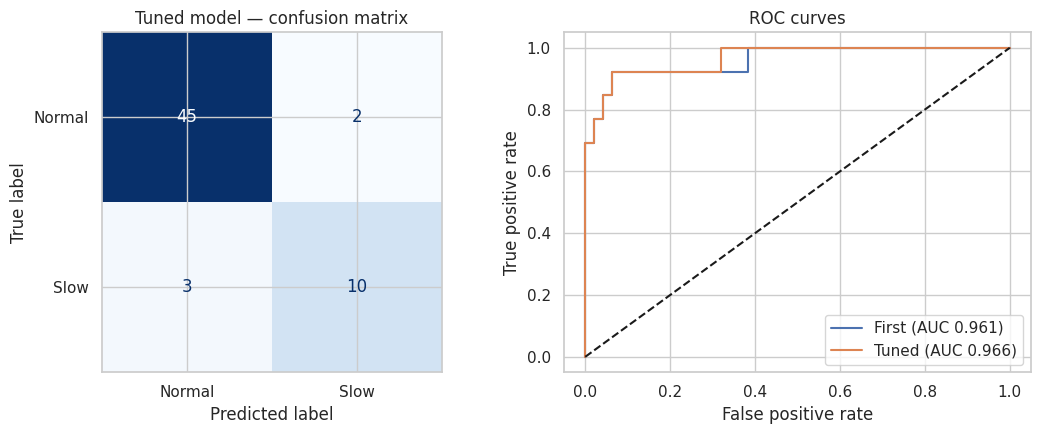

              precision    recall  f1-score   support

      Normal       0.94      0.96      0.95        47
        Slow       0.83      0.77      0.80        13

    accuracy                           0.92        60
   macro avg       0.89      0.86      0.87        60
weighted avg       0.91      0.92      0.92        60



In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred2), display_labels=['Normal', 'Slow']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Tuned model — confusion matrix')
for p, lab in [(prob1, 'First'), (prob2, 'Tuned')]:
    f, t, _ = roc_curve(y_test, p); ax[1].plot(f, t, label=f'{lab} (AUC {roc_auc_score(y_test, p):.3f})')
ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].set(title='ROC curves', xlabel='False positive rate', ylabel='True positive rate'); ax[1].legend()
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred2, target_names=['Normal', 'Slow']))

## Step 9 — Understand the model
Naive Bayes stores, for each class, the **average** and **variance** of every feature. Comparing them shows what a typical Slow attempt looks like compared with a typical Normal attempt. We also use **permutation importance** (shuffle one feature, see how much F1 drops) and check how correlated the features are, because that is where the "independence" assumption can hurt.

Class prior (Normal, Slow): [0.5 0.5]


,Normal mean,Slow mean,Normal std,Slow std
Log_Total_Time,-0.315,1.179,0.829,0.938
Log_Carry_Time,-0.304,1.137,0.849,0.938
Erasure_Count,-0.205,0.766,0.518,1.863
Carry_Ratio,0.038,-0.142,1.046,1.048
Non_Carry_Time,-0.225,0.841,0.595,1.730
Hint_Requests,-0.228,0.854,0.316,1.979
Operation_Type_Addition,0.246,0.240,0.534,0.531
Operation_Type_Division,0.235,0.280,0.529,0.549
Operation_Type_Multiplication,0.267,0.220,0.544,0.521
Operation_Type_Subtraction,0.251,0.260,0.537,0.541


(Numeric columns are standardised, so values are in standard-deviation units; the 0/1 operation columns show the share of each class in that operation.)


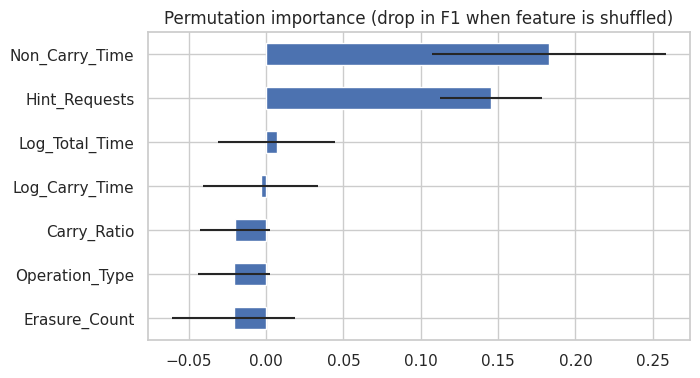

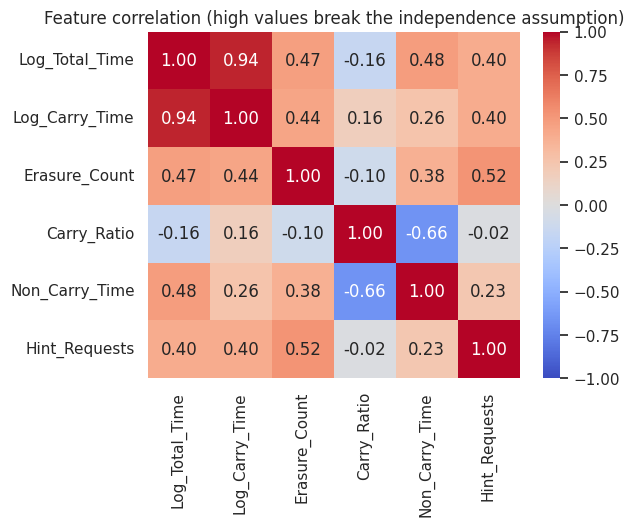

In [14]:
names = [n.split('__')[-1] for n in best_nb.named_steps['prep'].get_feature_names_out()]
gnb = best_nb.named_steps['nb']
means = pd.DataFrame(gnb.theta_.T, index=names, columns=['Normal mean', 'Slow mean'])
means['Normal std'] = np.sqrt(gnb.var_[0]); means['Slow std'] = np.sqrt(gnb.var_[1])
print('Class prior (Normal, Slow):', gnb.class_prior_.round(3))
display(means.round(3))
print('(Numeric columns are standardised, so values are in standard-deviation units; the 0/1 operation columns show the share of each class in that operation.)')

pi = permutation_importance(best_nb, X_test, y_test, scoring='f1', n_repeats=30, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values()
imp.plot(kind='barh', xerr=pd.Series(pi.importances_std, index=FEATURES)[imp.index], figsize=(7, 4),
         title='Permutation importance (drop in F1 when feature is shuffled)')
plt.show()

plt.figure(figsize=(6, 4.5))
sns.heatmap(X_train[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature correlation (high values break the independence assumption)'); plt.show()

### Threshold tuning (optional)
By default, P(Slow) ≥ 0.5 means "Slow". Lowering the threshold catches more slow learners (higher Recall) at the cost of more false alarms (lower Precision). Pick the cut-off that suits how the result will be used.

In [15]:
th = pd.DataFrame([{'threshold': t, 'precision': precision_score(y_test, prob2 >= t, zero_division=0),
                    'recall': recall_score(y_test, prob2 >= t), 'f1': f1_score(y_test, prob2 >= t)}
                   for t in np.arange(0.1, 0.91, 0.1)]).round(3)
th

,threshold,precision,recall,f1
0,0.1,0.786,0.846,0.815
1,0.2,0.846,0.846,0.846
2,0.3,0.846,0.846,0.846
3,0.4,0.846,0.846,0.846
4,0.5,0.833,0.769,0.800
5,0.6,0.909,0.769,0.833
6,0.7,0.909,0.769,0.833
7,0.8,0.909,0.769,0.833
8,0.9,0.909,0.769,0.833


## Step 10 — Final check, save and download
The tuned model is **retrained on all rows** and saved. Your backend needs:
* `nb_slow_learner_model.joblib` — the model (scaling and encoding are inside it)
* `nb_model_metadata.json` — feature order, threshold, scikit-learn version, test scores

In [16]:
THRESHOLD = 0.5       # set to your chosen cut-off from the table above

final_model = make_model(**{k.replace('nb__', ''): v for k, v in search.best_params_.items()})
final_model.fit(X, y)

os.makedirs('export', exist_ok=True)
joblib.dump(final_model, 'export/nb_slow_learner_model.joblib')

import sklearn
meta = {'model': 'GaussianNB', 'positive_class': 'Slow', 'threshold': THRESHOLD, 'use_hints': USE_HINTS,
        'best_params': {k: (v if isinstance(v, (int, float, str)) else str(v)) for k, v in search.best_params_.items()},
        'features_required_in_order': FEATURES,
        'raw_inputs': ['Operation_Type', 'Total_Time', 'Carry_Over_Time', 'Erasure_Count', 'Hint_Requests'],
        'operation_types': sorted(df['Operation_Type'].unique().tolist()),
        'test_metrics': {k: round(float(v), 4) for k, v in m2.items()}, 'sklearn_version': sklearn.__version__}
json.dump(meta, open('export/nb_model_metadata.json', 'w'), indent=2)
print(json.dumps(meta, indent=2))

{
  "model": "GaussianNB",
  "positive_class": "Slow",
  "threshold": 0.5,
  "use_hints": true,
  "best_params": {
    "nb__priors": "[0.5, 0.5]",
    "nb__var_smoothing": 0.1
  },
  "features_required_in_order": [
    "Log_Total_Time",
    "Log_Carry_Time",
    "Erasure_Count",
    "Carry_Ratio",
    "Non_Carry_Time",
    "Hint_Requests",
    "Operation_Type"
  ],
  "raw_inputs": [
    "Operation_Type",
    "Total_Time",
    "Carry_Over_Time",
    "Erasure_Count",
    "Hint_Requests"
  ],
  "operation_types": [
    "Addition",
    "Division",
    "Multiplication",
    "Subtraction"
  ],
  "test_metrics": {
    "Accuracy": 0.9167,
    "Balanced Accuracy": 0.8633,
    "Precision": 0.8333,
    "Recall": 0.7692,
    "F1": 0.8,
    "Specificity": 0.9574,
    "ROC-AUC": 0.9656,
    "MCC": 0.7484
  },
  "sklearn_version": "1.6.1"
}


In [17]:
# Try the saved model exactly as your backend will use it
def prepare_input(op, total_time, carry_time, erasures, hints=0):
    row = {'Operation_Type': op, 'Log_Total_Time': np.log1p(total_time), 'Log_Carry_Time': np.log1p(carry_time),
           'Erasure_Count': erasures, 'Hint_Requests': hints,
           'Carry_Ratio': carry_time / total_time if total_time else 0, 'Non_Carry_Time': total_time - carry_time}
    return pd.DataFrame([row])[meta['features_required_in_order']]

loaded = joblib.load('export/nb_slow_learner_model.joblib')
for case in [('Addition', 2.1, 2.1, 0, 0), ('Division', 70.0, 40.0, 2, 3)]:
    p = loaded.predict_proba(prepare_input(*case))[0, 1]
    print(case, '-> P(Slow) =', round(p, 3), '->', 'Slow' if p >= meta['threshold'] else 'Normal')

('Addition', 2.1, 2.1, 0, 0) -> P(Slow) = 0.0 -> Normal
('Division', 70.0, 40.0, 2, 3) -> P(Slow) = 1.0 -> Slow


In [18]:
import shutil
shutil.make_archive('nb_export', 'zip', 'export')
try:
    from google.colab import files
    files.download('nb_export.zip')
except ImportError:
    print('Saved nb_export.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Notes for your report / backend
* Install the **same scikit-learn version** in your backend as in `nb_model_metadata.json`.
* Scaling and one-hot encoding are inside the saved model, **but the log transform and the derived columns are not** — your backend must compute them exactly as `prepare_input` does (log1p of the two time columns, `Carry_Ratio`, `Non_Carry_Time`).
* Report the test scores above as your performance figures (they come from the model trained on 80%; the exported one is retrained on 100%).